# Part 2 — Classification and Model Improvement
**Student:** Sheila Shomang | **Student number:** ST10530465
**Task:** Predict whether a breast tumour is malignant or benign to help a medical scheme apply dreaded-disease (cancer) benefits faster.

Workflow: 1) Load and understand data → 2) EDA and cleaning → 3) Feature selection → 4) Train baseline → 5) Evaluate → 6) Retrain/improve → 7) Final test evaluation

In [1]:
# ---- Imports ----
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report, fbeta_score)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42          # fixed seed so results are reproducible
FIG = "figs/"              # folder where figures are saved for the report

## 1. Load the data
Dataset: Breast Cancer Wisconsin (Diagnostic) from the UCI Machine Learning Repository (Wolberg, Street & Mangasarian, 1995), loaded from the copy bundled with scikit-learn.
Each row is one breast mass; features are measurements computed from a digitised image of a fine needle aspirate (FNA).

In [2]:
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
# scikit-learn codes 0 = malignant, 1 = benign. For a cancer-detection task it is clearer and
# safer for metrics if the POSITIVE class (1) is the condition we want to detect: malignant.
df["malignant"] = 1 - df["target"]
df = df.drop(columns="target")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. Exploratory Data Analysis (EDA) and data cleaning

In [3]:
# 2.1 Structure: data types and missing values
print(df.dtypes.value_counts())
print("\nTotal missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

float64    30
int64       1
Name: count, dtype: int64

Total missing values: 0
Duplicate rows: 0


malignant
Benign       357
Malignant    212
Name: count, dtype: int64


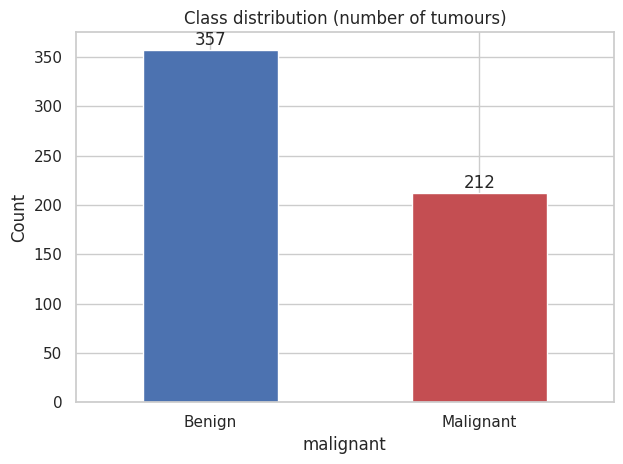

In [4]:
# 2.2 Target balance (counts)
counts = df["malignant"].value_counts().rename({0: "Benign", 1: "Malignant"})
print(counts)
ax = counts.plot(kind="bar", color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title("Class distribution (number of tumours)"); ax.set_ylabel("Count")
for i, v in enumerate(counts.values): ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout(); plt.savefig(FIG + "class_balance.png", dpi=150); plt.show()

In [5]:
# 2.3 Summary statistics and skewness
desc = df.describe().T[["mean", "std", "min", "max"]]
desc["skew"] = df.drop(columns="malignant").skew()
print(desc.round(3).head(12))
print("\nNumber of features with |skew| > 1:", int((desc["skew"].abs() > 1).sum()))
print("Note: ranges differ hugely (e.g. area vs smoothness) -> scaling is required for logistic regression.")

                           mean      std      min       max   skew
mean radius              14.127    3.524    6.981    28.110  0.942
mean texture             19.290    4.301    9.710    39.280  0.650
mean perimeter           91.969   24.299   43.790   188.500  0.991
mean area               654.889  351.914  143.500  2501.000  1.646
mean smoothness           0.096    0.014    0.053     0.163  0.456
mean compactness          0.104    0.053    0.019     0.345  1.190
mean concavity            0.089    0.080    0.000     0.427  1.401
mean concave points       0.049    0.039    0.000     0.201  1.171
mean symmetry             0.181    0.027    0.106     0.304  0.726
mean fractal dimension    0.063    0.007    0.050     0.097  1.304
radius error              0.405    0.277    0.112     2.873  3.089
texture error             1.217    0.552    0.360     4.885  1.646

Number of features with |skew| > 1: 22
Note: ranges differ hugely (e.g. area vs smoothness) -> scaling is required for logistic 

In [6]:
# 2.4 Outliers: count values outside 1.5 x IQR for each feature (counts only; we do NOT delete them)
feats = [c for c in df.columns if c != "malignant"]
q1, q3 = df[feats].quantile(0.25), df[feats].quantile(0.75)
iqr = q3 - q1
out_counts = ((df[feats] < q1 - 1.5 * iqr) | (df[feats] > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
print(out_counts.head(8))
print("Rows with at least one IQR outlier:", int(((df[feats] < q1 - 1.5*iqr) | (df[feats] > q3 + 1.5*iqr)).any(axis=1).sum()), "of", len(df))
# Decision: outliers in this dataset are real, often large malignant masses, so they carry signal. They are kept.

area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
dtype: int64
Rows with at least one IQR outlier: 171 of 569


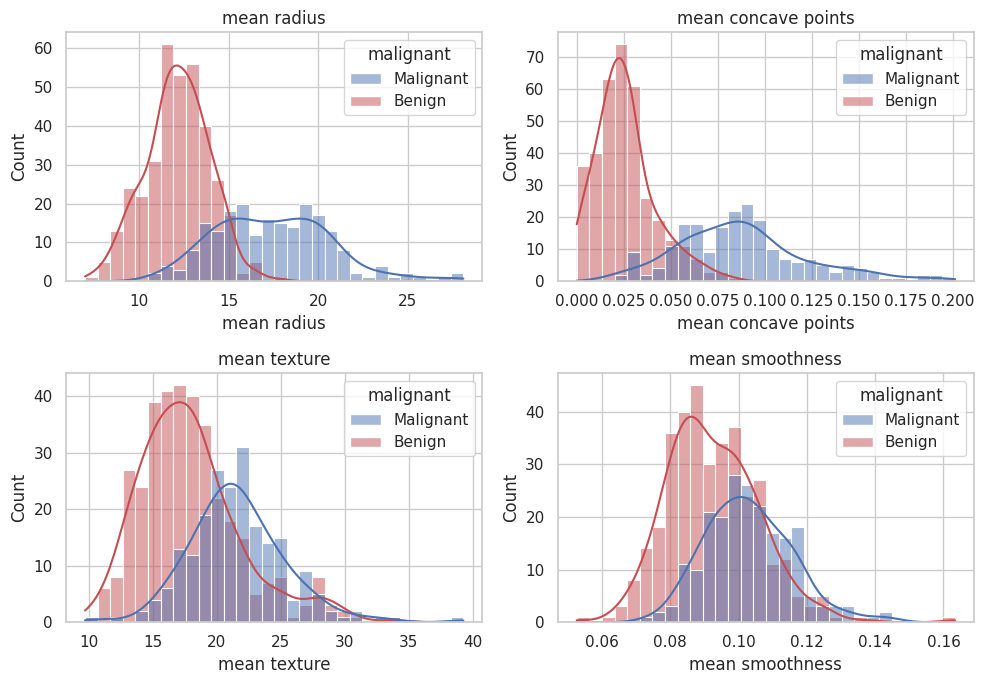

In [7]:
# 2.5 Feature distributions by class (most informative looking features)
show = ["mean radius", "mean concave points", "mean texture", "mean smoothness"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), show):
    sns.histplot(data=df, x=f, hue=df["malignant"].map({0: "Benign", 1: "Malignant"}),
                 bins=30, kde=True, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(f)
plt.tight_layout(); plt.savefig(FIG + "distributions.png", dpi=150); plt.show()

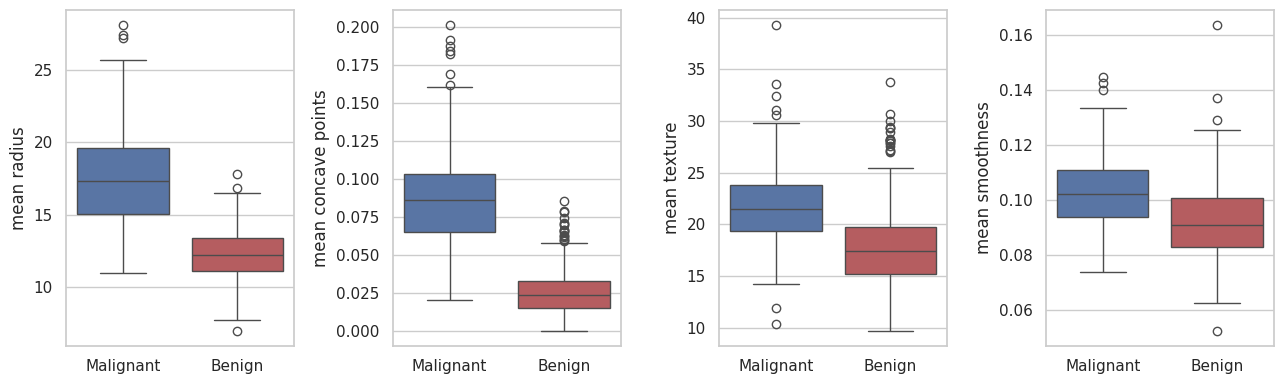

In [8]:
# 2.6 Boxplots: spread by class
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for ax, f in zip(axes, show):
    sns.boxplot(data=df, x=df["malignant"].map({0: "Benign", 1: "Malignant"}), y=f, ax=ax,
                palette=["#4C72B0", "#C44E52"])
    ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG + "boxplots.png", dpi=150); plt.show()

Top 8 features by |correlation| with malignant:
 worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
Name: malignant, dtype: float64


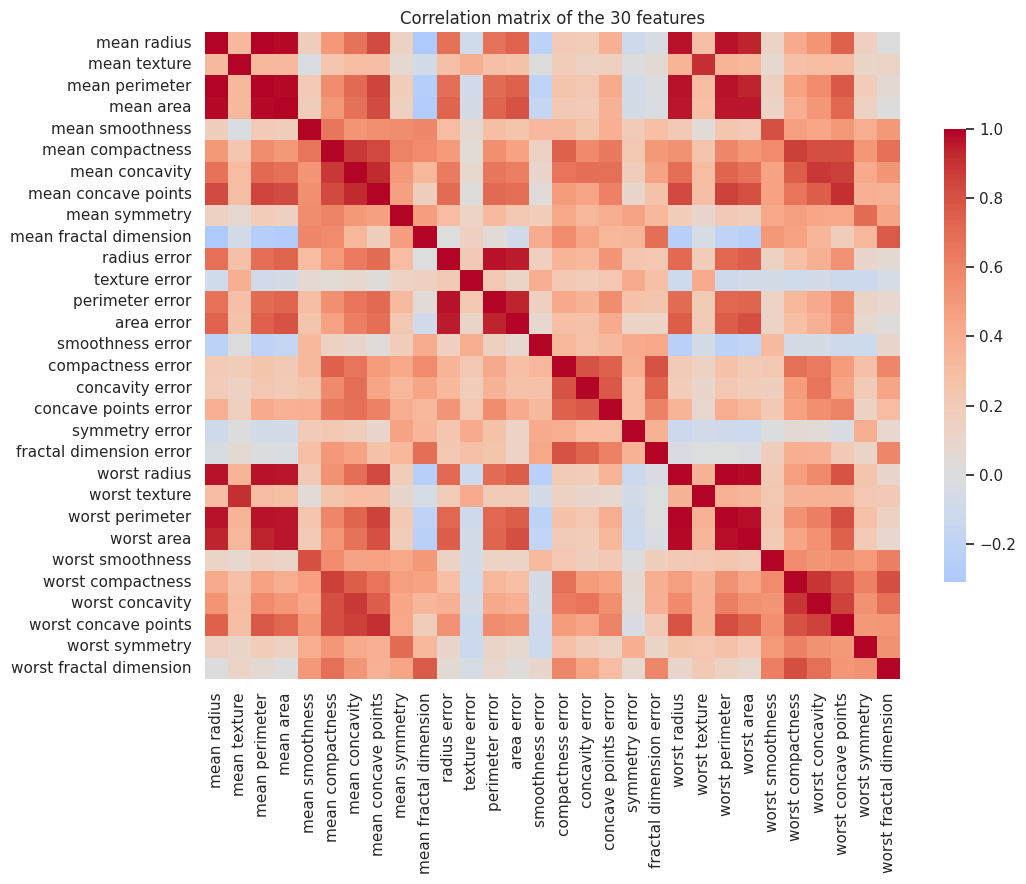

Feature pairs with |r| > 0.9: 21 -> strong multicollinearity (e.g. radius, perimeter, area)


In [9]:
# 2.7 Correlation with the target, and correlation between features (multicollinearity check)
corr_target = df.corr()["malignant"].drop("malignant").sort_values(key=np.abs, ascending=False)
print("Top 8 features by |correlation| with malignant:\n", corr_target.head(8).round(3))
corr = df[feats].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True, cbar_kws={"shrink": .7})
plt.title("Correlation matrix of the 30 features")
plt.tight_layout(); plt.savefig(FIG + "corr_heatmap.png", dpi=150); plt.show()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
n_pairs = int((upper.abs() > 0.9).sum().sum())
print("Feature pairs with |r| > 0.9:", n_pairs, "-> strong multicollinearity (e.g. radius, perimeter, area)")

**EDA findings:** no missing values or duplicates, so no imputation or row removal was needed. The classes are moderately imbalanced (benign is the majority).
Many features are strongly correlated (size-related measures), and features sit on very different scales. Therefore: split before any fitting, scale inside a pipeline, and reduce multicollinearity before p-value based selection.

## 3. Train / test split
A stratified 80/20 split keeps the class mix the same in both sets. The **test set is locked away** until the very end so the final score is an honest estimate. All selection and tuning use the training set only (prevents data leakage).

In [10]:
X = df[feats]; y = df["malignant"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| class counts (benign, malignant):", tuple(np.bincount(y_train)))
print("Test :", X_test.shape,  "| class counts (benign, malignant):", tuple(np.bincount(y_test)))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (455, 30) | class counts (benign, malignant): (np.int64(285), np.int64(170))
Test : (114, 30) | class counts (benign, malignant): (np.int64(72), np.int64(42))


## 4. Baseline model (Model 1): logistic regression, all 30 features, default hyperparameters

In [11]:
def make_pipe(C=1.0, class_weight=None):
    # Scaling is inside the pipeline so that, in cross-validation, it is fitted on training folds only.
    return Pipeline([("scale", StandardScaler()),
                     ("lr", LogisticRegression(C=C, class_weight=class_weight,
                                               max_iter=1000, random_state=RANDOM_STATE))])

scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
base = make_pipe()
cv_base = cross_validate(base, X_train, y_train, cv=cv, scoring=scoring)
cv_base_res = {k.replace("test_", ""): v.mean() for k, v in cv_base.items() if k.startswith("test_")}
print("Model 1 (baseline) 5-fold CV on training data:")
print({k: round(v, 4) for k, v in cv_base_res.items()})

Model 1 (baseline) 5-fold CV on training data:
{'accuracy': np.float64(0.9736), 'precision': np.float64(0.9771), 'recall': np.float64(0.9529), 'f1': np.float64(0.964), 'roc_auc': np.float64(0.9958)}


## 5. Feature selection (training data only)
Step A: remove one feature from each highly correlated pair (|r| > 0.8) to reduce multicollinearity. The 0.9 cut-off was tried first, but 20 correlated features left the logistic model near-perfectly separable and the maximum-likelihood fit failed to converge (p-values meaningless); 0.8 gives a stable fit.
Step B: backward elimination using p-values from a statsmodels Logit model (drop the least significant feature until all p < 0.05).

In [12]:
# Step A: correlation filter (training data only)
CORR_CUTOFF = 0.8
corr_tr = X_train.corr().abs()
upper_tr = corr_tr.where(np.triu(np.ones(corr_tr.shape), k=1).astype(bool))
# Keep the feature that is more strongly related to the target in each correlated pair
target_corr = X_train.apply(lambda s: abs(np.corrcoef(s, y_train)[0, 1]))
to_drop = set()
for col in upper_tr.columns:
    for row in upper_tr.index:
        if pd.notna(upper_tr.loc[row, col]) and upper_tr.loc[row, col] > CORR_CUTOFF:
            to_drop.add(row if target_corr[row] < target_corr[col] else col)
kept_A = [f for f in feats if f not in to_drop]
print("Dropped for collinearity:", len(to_drop), "| Remaining:", len(kept_A))

Dropped for collinearity: 18 | Remaining: 12


In [13]:
# Step B: backward elimination on standardised training features
scaler_sel = StandardScaler().fit(X_train[kept_A])
Xs = pd.DataFrame(scaler_sel.transform(X_train[kept_A]), columns=kept_A, index=X_train.index)
selected = kept_A.copy()
log = []
while True:
    m = sm.Logit(y_train, sm.add_constant(Xs[selected])).fit(disp=0, method="newton", maxiter=200)
    assert m.mle_retvals["converged"], "Logit did not converge"
    pvals = m.pvalues.drop("const")
    worst = pvals.idxmax()
    if pvals[worst] > 0.05:
        log.append((worst, round(pvals[worst], 4)))
        selected.remove(worst)
    else:
        break
print("Removed in order (feature, p-value):")
for f, p in log: print("  ", f, p)
print("\nFinal selected features (", len(selected), "):", selected)
final_sm = sm.Logit(y_train, sm.add_constant(Xs[selected])).fit(disp=0, method="newton", maxiter=200)
print(final_sm.summary2().tables[1].round(4))

Removed in order (feature, p-value):
   concave points error 0.9421
   worst smoothness 0.6461
   symmetry error 0.1993
   mean fractal dimension 0.0856
   mean symmetry 0.0521
   worst symmetry 0.4196

Final selected features ( 6 ): ['radius error', 'texture error', 'smoothness error', 'compactness error', 'worst texture', 'worst concave points']
                       Coef.  Std.Err.       z   P>|z|  [0.025   0.975]
const                -0.4247    0.3656 -1.1616  0.2454 -1.1413   0.2919
radius error          8.5493    1.9117  4.4720  0.0000  4.8024  12.2963
texture error        -3.2827    0.8344 -3.9340  0.0001 -4.9181  -1.6472
smoothness error      0.5499    0.2759  1.9933  0.0462  0.0092   1.0907
compactness error    -1.7315    0.5858 -2.9559  0.0031 -2.8797  -0.5834
worst texture         4.6468    1.0211  4.5507  0.0000  2.6454   6.6481
worst concave points  6.0595    1.1880  5.1007  0.0000  3.7311   8.3879


## 6. Evaluate the baseline on a validation basis and expose its shortcoming
In a dreaded-disease context a **false negative** (a cancer case predicted benign) is the costly error, so **recall** for the malignant class is the priority metric, supported by precision, F1 and ROC-AUC. Accuracy alone can hide this.

In [14]:
# Out-of-fold predictions on training data for the baseline (no test data used)
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(base, X_train, y_train, cv=cv)
cm = confusion_matrix(y_train, oof)
print("Baseline confusion matrix (cross-validated, training data) [rows=actual, cols=predicted]:\n", cm)
print("Missed malignant (false negatives):", cm[1, 0], "| False alarms (false positives):", cm[0, 1])

Baseline confusion matrix (cross-validated, training data) [rows=actual, cols=predicted]:
 [[281   4]
 [  8 162]]
Missed malignant (false negatives): 8 | False alarms (false positives): 4


## 7. Retraining with different parameters (Model 2, Model 3, then Model 4)
Hyperparameters searched with 5-fold CV on the **training set only**:
- `C` (inverse regularisation strength): smaller = stronger regularisation, less overfitting
- `penalty`: L2 (ridge) or L1 (lasso, can zero-out weak features)
- `class_weight`: none or "balanced" (penalises missing the minority malignant class more)
Scoring metric for the search: **F2** (weights recall twice as much as precision) because missed cancers are costlier.

- **Model 2:** the 6 features chosen by backward elimination + tuned parameters
- **Model 3:** all 30 features + tuned parameters (regularisation copes with correlated features)

In [15]:
from sklearn.metrics import make_scorer
f2 = make_scorer(fbeta_score, beta=2)
param_grid = {"lr__C": [0.01, 0.1, 1, 10, 100],
              "lr__penalty": ["l1", "l2"],
              "lr__solver": ["liblinear"],
              "lr__class_weight": [None, "balanced"]}

# Model 2: selected features
gs2 = GridSearchCV(make_pipe(), param_grid, cv=cv, scoring=f2, n_jobs=-1).fit(X_train[selected], y_train)
model2 = gs2.best_estimator_
# Model 3: all features
gs3 = GridSearchCV(make_pipe(), param_grid, cv=cv, scoring=f2, n_jobs=-1).fit(X_train, y_train)
model3 = gs3.best_estimator_
print("Model 2 best params:", gs2.best_params_)
print("Model 3 best params:", gs3.best_params_)

cands = {"Model 1 (all 30, default)": (base, feats),
         "Model 2 (6 selected, tuned)": (model2, selected),
         "Model 3 (all 30, tuned)": (model3, feats)}
rows = {}
for name, (mdl, cols) in cands.items():
    r = cross_validate(mdl, X_train[cols], y_train, cv=cv, scoring={**scoring, "f2": f2})
    rows[name] = {k.replace("test_", ""): v.mean() for k, v in r.items() if k.startswith("test_")}
cv_table = pd.DataFrame(rows).round(4)
print(cv_table)
best_name = cv_table.loc["f2"].idxmax()
print("\nBest candidate by cross-validated F2 (training data only):", best_name)

Model 2 best params: {'lr__C': 1, 'lr__class_weight': 'balanced', 'lr__penalty': 'l1', 'lr__solver': 'liblinear'}
Model 3 best params: {'lr__C': 0.1, 'lr__class_weight': 'balanced', 'lr__penalty': 'l2', 'lr__solver': 'liblinear'}


           Model 1 (all 30, default)  Model 2 (6 selected, tuned)  \
accuracy                      0.9736                       0.9626   
precision                     0.9771                       0.9428   
recall                        0.9529                       0.9588   
f1                            0.9640                       0.9503   
roc_auc                       0.9958                       0.9920   
f2                            0.9572                       0.9553   

           Model 3 (all 30, tuned)  
accuracy                    0.9758  
precision                   0.9766  
recall                      0.9588  
f1                          0.9674  
roc_auc                     0.9949  
f2                          0.9622  

Best candidate by cross-validated F2 (training data only): Model 3 (all 30, tuned)


### Model 4: decision-threshold tuning
Logistic regression predicts a probability; the default rule "malignant if p >= 0.5" is not sacred. Lowering the threshold catches more cancers (higher recall) at the cost of more false alarms.
The threshold is chosen using **out-of-fold** training predictions (never the test set) to maximise F2.

 threshold  recall  precision     f2  FN  FP
      0.10  0.9941     0.6898 0.9135   1  76
      0.15  0.9941     0.7578 0.9358   1  54
      0.20  0.9941     0.8164 0.9526   1  38
      0.25  0.9824     0.8608 0.9554   3  27
      0.30  0.9824     0.9027 0.9653   3  18
      0.35  0.9824     0.9382 0.9732   3  11
      0.40  0.9765     0.9432 0.9696   4  10
      0.45  0.9706     0.9538 0.9672   5   8
      0.50  0.9588     0.9760 0.9622   7   4
      0.55  0.9412     0.9816 0.9490  10   3
      0.60  0.9353     0.9876 0.9453  11   2
      0.65  0.9294     0.9937 0.9416  12   1
      0.70  0.9059     1.0000 0.9233  16   0
      0.75  0.8941     1.0000 0.9135  18   0
      0.80  0.8588     1.0000 0.8838  24   0
      0.85  0.8471     1.0000 0.8738  26   0
      0.90  0.7941     1.0000 0.8282  35   0

Chosen threshold (max out-of-fold F2): 0.35


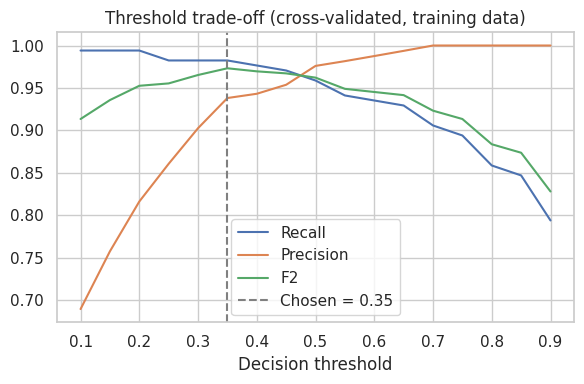

In [16]:
best_model, best_cols = cands[best_name]
oof_prob = cross_val_predict(best_model, X_train[best_cols], y_train, cv=cv, method="predict_proba")[:, 1]
grid_t = np.round(np.arange(0.10, 0.91, 0.05), 2)
t_rows = []
for t in grid_t:
    p = (oof_prob >= t).astype(int)
    t_rows.append({"threshold": t, "recall": recall_score(y_train, p), "precision": precision_score(y_train, p),
                   "f2": fbeta_score(y_train, p, beta=2), "FN": int(((p == 0) & (y_train == 1)).sum()),
                   "FP": int(((p == 1) & (y_train == 0)).sum())})
t_df = pd.DataFrame(t_rows).round(4)
print(t_df.to_string(index=False))
best_t = float(t_df.loc[t_df["f2"].idxmax(), "threshold"])
print("\nChosen threshold (max out-of-fold F2):", best_t)

plt.figure(figsize=(6, 4))
plt.plot(t_df["threshold"], t_df["recall"], label="Recall"); plt.plot(t_df["threshold"], t_df["precision"], label="Precision")
plt.plot(t_df["threshold"], t_df["f2"], label="F2"); plt.axvline(best_t, color="grey", ls="--", label=f"Chosen = {best_t}")
plt.xlabel("Decision threshold"); plt.title("Threshold trade-off (cross-validated, training data)")
plt.legend(); plt.tight_layout(); plt.savefig(FIG + "threshold.png", dpi=150); plt.show()

## 8. Final evaluation on the untouched test set
All models are fitted on the full training set and scored once on the test set. The model is selected from the cross-validation evidence above, not from these test scores.

In [17]:
for _, (mdl, cols) in cands.items():
    mdl.fit(X_train[cols], y_train)

def metrics_from(prob, pred):
    return {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
            "f2": fbeta_score(y_test, pred, beta=2), "roc_auc": roc_auc_score(y_test, prob)}

test_res, test_cm = {}, {}
for name, (mdl, cols) in cands.items():
    prob = mdl.predict_proba(X_test[cols])[:, 1]
    pred = (prob >= 0.5).astype(int)
    test_res[name] = metrics_from(prob, pred); test_cm[name] = confusion_matrix(y_test, pred).ravel()
# Model 4 = best CV candidate + tuned threshold
prob4 = best_model.predict_proba(X_test[best_cols])[:, 1]
pred4 = (prob4 >= best_t).astype(int)
name4 = f"Model 4 ({best_name.split(' (')[0]} + threshold {best_t})"
test_res[name4] = metrics_from(prob4, pred4); test_cm[name4] = confusion_matrix(y_test, pred4).ravel()
res = pd.DataFrame(test_res).round(4)
print(res.to_string())
for k, (tn, fp, fn, tp) in test_cm.items():
    print(f"{k}: TN={tn} FP={fp} FN={fn} TP={tp}")

           Model 1 (all 30, default)  Model 2 (6 selected, tuned)  Model 3 (all 30, tuned)  Model 4 (Model 3 + threshold 0.35)
accuracy                      0.9649                       0.9474                   0.9912                              0.9561
precision                     0.9750                       0.9500                   1.0000                              0.9111
recall                        0.9286                       0.9048                   0.9762                              0.9762
f1                            0.9512                       0.9268                   0.9880                              0.9425
f2                            0.9375                       0.9135                   0.9809                              0.9624
roc_auc                       0.9960                       0.9907                   0.9977                              0.9977
Model 1 (all 30, default): TN=71 FP=1 FN=3 TP=39
Model 2 (6 selected, tuned): TN=70 FP=2 FN=4 TP=38
Model 3 (al

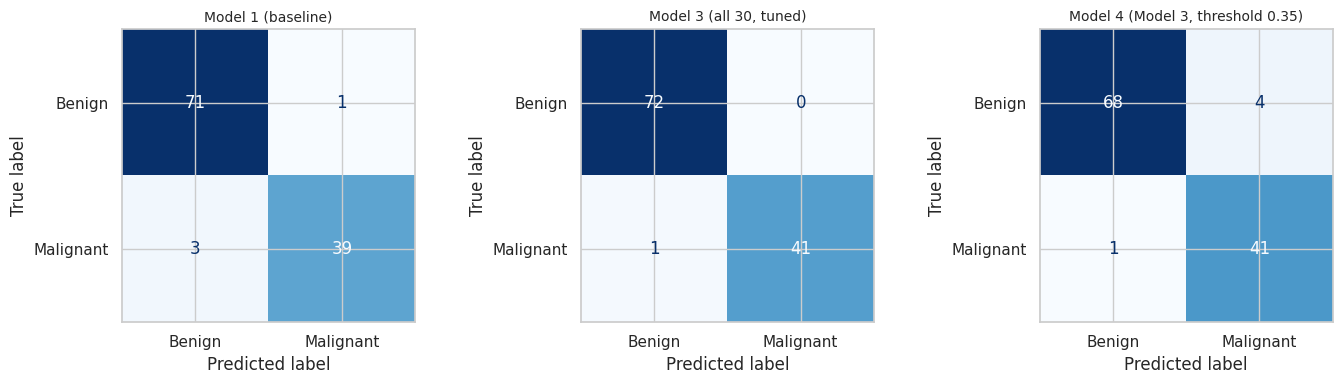

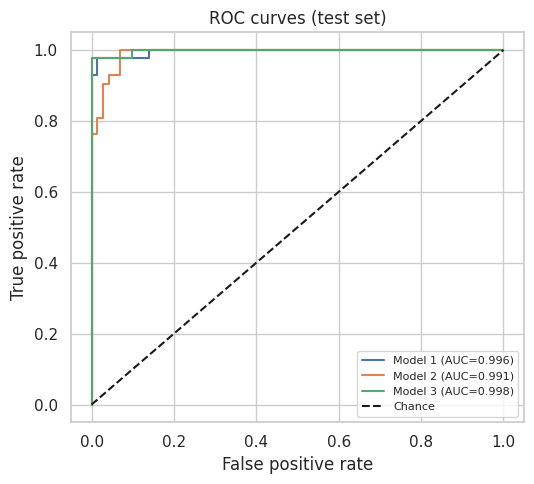

In [18]:
# Confusion matrices: baseline, tuned all-feature model, threshold-tuned model
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
panels = [("Model 1 (baseline)", cands["Model 1 (all 30, default)"][0].predict_proba(X_test[feats])[:, 1] >= 0.5),
          ("Model 3 (all 30, tuned)", cands["Model 3 (all 30, tuned)"][0].predict_proba(X_test[feats])[:, 1] >= 0.5),
          ("Model 4 (Model 3, threshold " + str(best_t) + ")", pred4 == 1)]
for ax, (nm, pred) in zip(axes, panels):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred.astype(int)), display_labels=["Benign", "Malignant"]).plot(cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nm, fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "confusion_matrices.png", dpi=150); plt.show()

# ROC curves
plt.figure(figsize=(5.5, 5))
for name, (mdl, cols) in cands.items():
    pr = mdl.predict_proba(X_test[cols])[:, 1]; fpr, tpr, _ = roc_curve(y_test, pr)
    plt.plot(fpr, tpr, label=f"{name.split(' (')[0]} (AUC={roc_auc_score(y_test, pr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves (test set)")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG + "roc.png", dpi=150); plt.show()

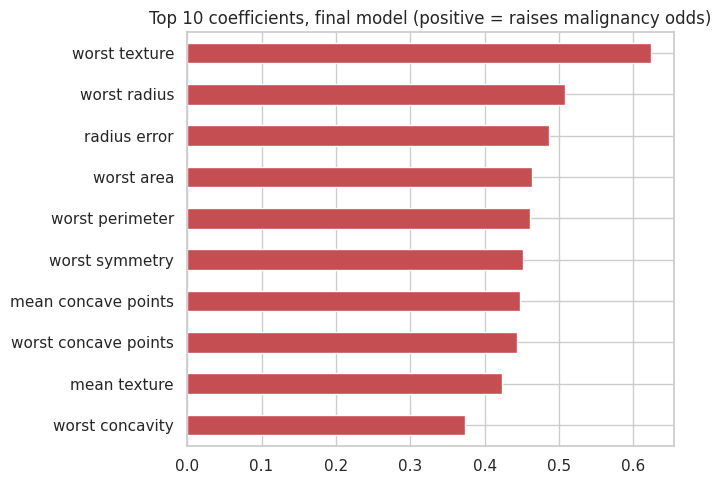

worst concavity         0.374
mean texture            0.424
worst concave points    0.443
mean concave points     0.448
worst symmetry          0.452
worst perimeter         0.462
worst area              0.464
radius error            0.486
worst radius            0.508
worst texture           0.624
dtype: float64


In [19]:
# Which features drive the final model? Coefficients on standardised features
coefs = pd.Series(best_model.named_steps["lr"].coef_[0], index=best_cols)
coefs = coefs[coefs != 0].sort_values(key=np.abs, ascending=False).head(10).sort_values()
plt.figure(figsize=(7, 5)); coefs.plot(kind="barh", color=np.where(coefs > 0, "#C44E52", "#4C72B0"))
plt.title("Top 10 coefficients, final model (positive = raises malignancy odds)"); plt.tight_layout()
plt.savefig(FIG + "coefs.png", dpi=150); plt.show()
print(coefs.round(3))

In [20]:
# Save key results so the written report is built from the real outputs
import json
json.dump({"cv": cv_table.to_dict(), "test": res.to_dict(), "cm": {k: [int(x) for x in v] for k, v in test_cm.items()},
           "best_t": best_t, "best_name": best_name, "selected": selected, "n_dropped_corr": len(to_drop),
           "p_log": log, "gs2": {k: str(v) for k, v in gs2.best_params_.items()}, "gs3": {k: str(v) for k, v in gs3.best_params_.items()},
           "t_table": t_df.to_dict("records"), "n_outlier_rows": int(((df[feats] < q1 - 1.5*iqr) | (df[feats] > q3 + 1.5*iqr)).any(axis=1).sum()),
           "n_skew": int((desc["skew"].abs() > 1).sum()), "n_pairs": n_pairs,
           "top_corr": corr_target.head(5).round(3).to_dict(), "coefs": coefs.round(3).to_dict()}, open("results.json", "w"), indent=1)

## 9. Limitations
- The test set is small (114 tumours), so one more or fewer error changes the scores noticeably; cross-validation results are more stable.
- The dataset has 569 tumours from one source; the model has not been validated on other populations or imaging equipment.
- The model supports, and does not replace, clinical judgement and the scheme's claims assessment.